# Guruswami--Sudan list decoding, off the shelf

The encoder notebooks stop at Proposition 1. The paper's §IV-B goes further: turning
per-coordinate histograms back into Reed--Solomon codewords needs **list decoding** of
Reed--Solomon, and that is what Guruswami--Sudan provides.

The point of list decoding: classical unique decoding corrects up to
$\lfloor (d-1)/2 \rfloor$ errors, because beyond half the minimum distance the answer
stops being unique. Guruswami--Sudan gives up on uniqueness and returns a *short list*
guaranteed to contain every codeword within a radius $\tau$, which can go all the way out
to the **Johnson radius** $n - \sqrt{n(n-d)}$.

## Where this decoder comes from

There is no dedicated Guruswami--Sudan package on PyPI --- I checked `guruswami-sudan`,
`guruswami`, `list-decoding`, `codinglib`, and the RS libraries `galois`, `komm` and
`reedsolo` all implement unique decoding only. The one real off-the-shelf implementation
is **SageMath's** `GRSGuruswamiSudanDecoder`, and it is reachable from plain Python via
[passagemath](https://github.com/passagemath/passagemath), the pip-installable fork of
Sage that ships binary wheels.

```
uv sync --group sage
```

It is kept in its own dependency group because it is around 200 MB and nothing else in
this project needs it.

## Two things that will bite you

1. **Bootstrap first.** Importing `sage.coding...` directly raises
   `ImportError: cannot import name Category` from a circular import. Importing
   `sage.all__sagemath_modules` first fixes the initialisation order.
2. **Pass `interpolation_alg="LinearAlgebra"`.** The default Lee--O'Sullivan
   interpolation **segfaults** inside NTL on this build (caught by `cysignals` and
   re-raised as `SignalError`). The linear-algebra path gives identical results and is
   fast enough here.

In [1]:
import random

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# 1. bootstrap Sage BEFORE touching sage.coding, or you get a circular ImportError
import sage.all__sagemath_modules as _sage_bootstrap

from sage.coding.grs_code import GeneralizedReedSolomonCode, GRSBerlekampWelchDecoder
from sage.coding.guruswami_sudan.gs_decoder import GRSGuruswamiSudanDecoder
from sage.coding.decoder import DecodingError
from sage.rings.finite_rings.finite_field_constructor import GF

%matplotlib inline
np.set_printoptions(precision=3, suppress=True, linewidth=120)

import sage.version
print("passagemath / Sage version:", sage.version.version)
print("decoder:", GRSGuruswamiSudanDecoder)

passagemath / Sage version: 10.8.10
decoder: <class 'sage.coding.guruswami_sudan.gs_decoder.GRSGuruswamiSudanDecoder'>


## The same code the encoder notebooks use

To make this notebook comparable with [encode_m.ipynb](encode_m.ipynb) rather than a
standalone toy, the Reed--Solomon code here is built to be *identical* to the one there:

- the **same modulus**, taken from `encode_m.ipynb`'s `find_irreducible`, so Sage's
  $\mathbb{F}_{p^m}$ has the same element-to-digit correspondence as ours;
- the **same evaluation points**, in the same order --- all $N = p^m$ field elements,
  indexed by our integer encoding $0, 1, \ldots, N-1$.

With those two matched, our `reed_solomon_encode` and Sage's polynomial evaluation must
agree exactly, and the cell below asserts it. That matters: it means anything this
notebook decodes is a codeword of the code the other notebooks encode.

In [2]:
def load_notebook_defs(path, skip=("plt.subplots", "fig.savefig")):
    """exec another notebook's code cells, skipping figures and magics."""
    import contextlib, io, json
    nb = json.loads(open(path).read())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        if any(k in src for k in skip):
            continue
        src = "\n".join(("# " + ln) if ln.lstrip()[:1] in ("%", "!") else ln
                        for ln in src.split("\n"))
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(src, path, "exec"), ns)
        except Exception:
            pass
    return ns


enc = load_notebook_defs("encode_m.ipynb")
p, m, K = 2, 4, 2                      # the p=2, m=4, K=2 code from encode_m.ipynb
N = p ** m
vec, ADD, MUL = enc["gf_tables"](p, m)
modulus = enc["find_irreducible"](p, m)
print(f"encode_m.ipynb modulus (low -> high): {modulus}")

# force Sage to use OUR modulus, so digit vectors line up
F = GF(N, "a", modulus=modulus)
gen = F.gen()
print(f"sage field: {F}   modulus {F.modulus().list()}")
assert F.modulus().list() == modulus


def to_sage(i):
    """our integer encoding -> Sage field element, via the digit vector"""
    return sum(int(c) * gen ** k for k, c in enumerate(vec[i]))


from_sage = {to_sage(i): i for i in range(N)}
assert len(from_sage) == N, "int <-> field mapping is not a bijection"

points = [to_sage(j) for j in range(N)]          # our evaluation order
CODE = GeneralizedReedSolomonCode(points, K)
print(f"\n{CODE}")

# the two encoders agree, so this really is the other notebook's code
Rx = CODE.base_field()["x"]
_rng = np.random.default_rng(0)
for _ in range(30):
    u = [int(x) for x in _rng.integers(0, N, K)]
    ours = enc["reed_solomon_encode"](u, p, m, (vec, ADD, MUL))
    theirs = [from_sage[Rx([to_sage(c) for c in u])(x)] for x in points]
    assert theirs == list(ours), (u, list(ours), theirs)
print("reed_solomon_encode agrees with Sage's evaluation on 30/30 random messages")

encode_m.ipynb modulus (low -> high): [1, 0, 0, 1, 1]
sage field: Finite Field in a of size 2^4   modulus [1, 0, 0, 1, 1]

[16, 2, 15] Reed-Solomon Code over GF(16)
reed_solomon_encode agrees with Sage's evaluation on 30/30 random messages


## Three radii

| Radius | Formula | Meaning |
|---|---|---|
| Unique decoding | $\lfloor (d-1)/2 \rfloor$ | beyond this, the nearest codeword may not be unique |
| Guruswami--Sudan $\tau$ | tunable, $< $ Johnson | the list is guaranteed to contain every codeword within $\tau$ |
| Johnson | $n - \sqrt{n(n-d)}$ | a hard ceiling; $\tau$ must stay strictly below it |

Each $\tau$ needs interpolation parameters $(s, \ell)$ --- the multiplicity and the list
size bound. Larger $\tau$ costs larger $(s, \ell)$ and so more work.

In [3]:
import math

n, k = CODE.length(), CODE.dimension()
d = CODE.minimum_distance()
unique_radius = (d - 1) // 2
johnson = n - math.sqrt(n * (n - d))

print(f"code: [n={n}, k={k}, d={d}] over GF({N})   rate = {k}/{n}")
print(f"unique-decoding radius : {unique_radius}")
print(f"Johnson radius         : {johnson:.3f}")

print(f"\n{'tau':>4} {'(s, ell)':>10}  status")
taus = {}
for tau in range(unique_radius, int(math.ceil(johnson)) + 2):
    try:
        D = GRSGuruswamiSudanDecoder(CODE, tau=tau, interpolation_alg="LinearAlgebra")
        taus[tau] = D
        flag = "" if tau <= unique_radius else "  <- beyond unique decoding"
        print(f"{tau:>4} {str(D.parameters()):>10}  ok{flag}")
    except Exception as e:
        print(f"{tau:>4} {'--':>10}  {type(e).__name__}: {str(e)[:52]}")

TAU = max(taus)
DECODER = taus[TAU]
print(f"\nusing tau = {TAU}: corrects {TAU} errors where unique decoding "
      f"manages {unique_radius}")
print(f"that is {TAU / unique_radius:.2f}x the radius, at (s, ell) = {DECODER.parameters()}")

code: [n=16, k=2, d=15] over GF(16)   rate = 2/16
unique-decoding radius : 7
Johnson radius         : 12.000

 tau   (s, ell)  status
   7     (1, 1)  ok
   8     (1, 2)  ok  <- beyond unique decoding
   9     (1, 2)  ok  <- beyond unique decoding
  10     (1, 3)  ok  <- beyond unique decoding
  11     (2, 6)  ok  <- beyond unique decoding
  12         --  ValueError: The decoding radius must be less than the Johnson ra
  13         --  ValueError: The decoding radius must be less than the Johnson ra

using tau = 11: corrects 11 errors where unique decoding manages 7
that is 1.57x the radius, at (s, ell) = (2, 6)


## One decode, past the unique-decoding radius

Take a real codeword, corrupt more positions than unique decoding can handle, and list
decode. The list is short and the true codeword is in it.

In [4]:
NONZERO = [x for x in F if x != F.zero()]


def corrupt(codeword, n_errors, rng):
    """Add a random nonzero error in n_errors distinct positions."""
    r = list(codeword)
    for i in rng.sample(range(len(r)), n_errors):
        r[i] += rng.choice(NONZERO)
    return CODE.ambient_space()(r)


rng = random.Random(0)
sent = CODE.random_element()
received = corrupt(sent, TAU, rng)
n_wrong = sum(1 for a, b in zip(sent, received) if a != b)
print(f"sent a codeword, corrupted {n_wrong} of {n} positions "
      f"(unique decoding maxes at {unique_radius})\n")

# what unique decoding makes of it
try:
    bw = GRSBerlekampWelchDecoder(CODE).decode_to_code(received)
    print("Berlekamp-Welch:", "correct" if bw == sent else "returned a WRONG codeword")
except (DecodingError, ZeroDivisionError) as e:
    print(f"Berlekamp-Welch: failed ({type(e).__name__}) -- as expected past its radius")

# what Guruswami-Sudan makes of it
candidates = DECODER.decode_to_code(received)
print(f"\nGuruswami-Sudan returned a list of {len(candidates)} candidate(s):")
for i, c in enumerate(candidates):
    dist = sum(1 for a, b in zip(c, received) if a != b)
    msg = [from_sage[x] for x in CODE.unencode(c)]
    print(f"  [{i}] distance {dist:>2} from received, message {msg}"
          f"{'   <- the one that was sent' if c == sent else ''}")
assert any(c == sent for c in candidates), "GS must return the true codeword"
print("\nthe transmitted codeword is in the list: True")

sent a codeword, corrupted 11 of 16 positions (unique decoding maxes at 7)

Berlekamp-Welch: failed (DecodingError) -- as expected past its radius

Guruswami-Sudan returned a list of 1 candidate(s):
  [0] distance 11 from received, message [5, 4]   <- the one that was sent

the transmitted codeword is in the list: True


## How much does list decoding actually buy?

Sweep the number of errors from 0 up past the Johnson radius. At each level, compare:

- **unique decoding** (Berlekamp--Welch) --- did it return the *correct* codeword? Note
  that past its radius it can either fail cleanly or return a confidently wrong answer,
  so those are counted separately.
- **Guruswami--Sudan** --- is the true codeword somewhere in the returned list?

In [5]:
MODE = "light"
PALETTE = {
    "light": {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e",
              "grid": "#dcdbd6", "series": ["#2a78d6", "#eb6834", "#1baf7a"]},
    "dark":  {"surface": "#1a1a19", "ink": "#ffffff", "ink2": "#c3c2b7",
              "grid": "#3a3a38", "series": ["#3987e5", "#d95926", "#199e70"]},
}
PAL = PALETTE[MODE]
mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "axes.edgecolor": PAL["grid"], "grid.color": PAL["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 130,
})
import os
os.makedirs("figures", exist_ok=True)
print(f"plot style: {MODE}, series {PAL['series']}")

plot style: light, series ['#2a78d6', '#eb6834', '#1baf7a']


In [6]:
TRIALS = 20
ERRS = list(range(0, min(n, int(johnson)) + 2))
BW = GRSBerlekampWelchDecoder(CODE)
rng = random.Random(1)

rows = []
for e in ERRS:
    bw_ok = bw_wrong = bw_fail = gs_ok = 0
    sizes = []
    for _ in range(TRIALS):
        sent = CODE.random_element()
        received = corrupt(sent, e, rng)
        try:
            out = BW.decode_to_code(received)
            bw_ok += out == sent
            bw_wrong += out != sent
        except (DecodingError, ZeroDivisionError):
            bw_fail += 1
        try:
            lst = DECODER.decode_to_code(received)
            sizes.append(len(lst))
            gs_ok += any(c == sent for c in lst)
        except (DecodingError, ZeroDivisionError):
            sizes.append(0)
    rows.append(dict(errors=e,
                     bw_correct=100 * bw_ok / TRIALS,
                     bw_wrong=100 * bw_wrong / TRIALS,
                     bw_failed=100 * bw_fail / TRIALS,
                     gs_correct=100 * gs_ok / TRIALS,
                     mean_list=float(np.mean(sizes)),
                     max_list=max(sizes)))

print(f"{'errs':>5} {'BW correct':>11} {'BW wrong':>9} {'BW failed':>10} "
      f"{'GS in list':>11} {'mean list':>10} {'max list':>9}")
print("-" * 70)
for r in rows:
    print(f"{r['errors']:>5} {r['bw_correct']:>10.0f}% {r['bw_wrong']:>8.0f}% "
          f"{r['bw_failed']:>9.0f}% {r['gs_correct']:>10.0f}% "
          f"{r['mean_list']:>10.2f} {r['max_list']:>9}")

# the guarantees must hold exactly where the theory says they do
for r in rows:
    if r["errors"] <= unique_radius:
        assert r["bw_correct"] == 100, f"unique decoding failed at e={r['errors']}"
    if r["errors"] <= TAU:
        assert r["gs_correct"] == 100, f"GS missed the codeword at e={r['errors']}"
print(f"\nunique decoding is exact for e <= {unique_radius}; "
      f"GS is exact for e <= {TAU}. Both asserted.")

 errs  BW correct  BW wrong  BW failed  GS in list  mean list  max list
----------------------------------------------------------------------
    0        100%        0%         0%        100%       1.00         1
    1        100%        0%         0%        100%       1.00         1
    2        100%        0%         0%        100%       1.00         1
    3        100%        0%         0%        100%       1.00         1
    4        100%        0%         0%        100%       1.00         1
    5        100%        0%         0%        100%       1.00         1
    6        100%        0%         0%        100%       1.10         2
    7        100%        0%         0%        100%       1.10         2
    8          0%        0%       100%        100%       1.20         2
    9          0%        0%       100%        100%       1.40         2
   10          0%        0%       100%        100%       1.30         3
   11          0%        0%       100%        100%       1.30    

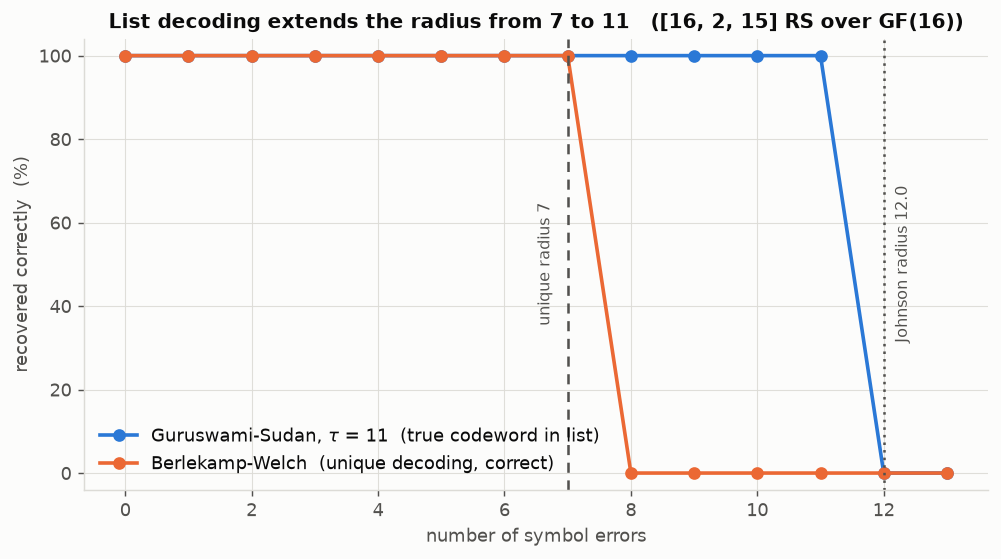

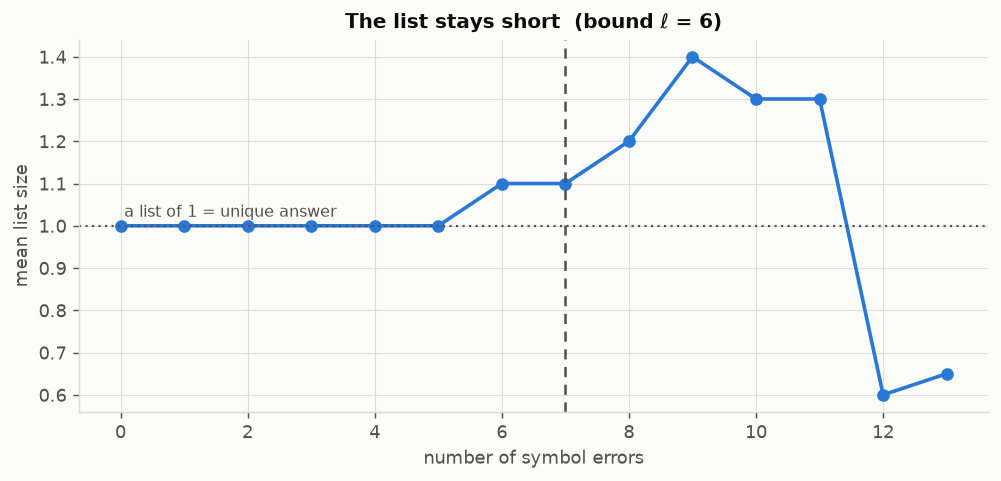

list-size bound from the (s, ell) parameters: ell = 6
largest list actually seen:                   3


In [7]:
xs = [r["errors"] for r in rows]

fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.plot(xs, [r["gs_correct"] for r in rows], color=PAL["series"][0], marker="o",
        label=f"Guruswami-Sudan, $\\tau$ = {TAU}  (true codeword in list)")
ax.plot(xs, [r["bw_correct"] for r in rows], color=PAL["series"][1], marker="o",
        label="Berlekamp-Welch  (unique decoding, correct)")
ax.axvline(unique_radius, color=PAL["ink2"], linestyle=(0, (4, 3)), linewidth=1.4)
ax.annotate(f"unique radius {unique_radius}", (unique_radius, 50), xytext=(-8, 0),
            textcoords="offset points", color=PAL["ink2"], fontsize=9,
            rotation=90, va="center", ha="right")
ax.axvline(johnson, color=PAL["ink2"], linestyle=(0, (1, 2)), linewidth=1.4)
ax.annotate(f"Johnson radius {johnson:.1f}", (johnson, 50), xytext=(6, 0),
            textcoords="offset points", color=PAL["ink2"], fontsize=9,
            rotation=90, va="center")
ax.set_xlabel("number of symbol errors")
ax.set_ylabel("recovered correctly  (%)")
ax.set_ylim(-4, 104)
ax.set_xticks(xs[::2])
ax.set_title(f"List decoding extends the radius from {unique_radius} to {TAU}"
             f"   ([{n}, {k}, {d}] RS over GF({N}))")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figures/gs_vs_unique.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.8, 3.8))
ax.plot(xs, [r["mean_list"] for r in rows], color=PAL["series"][0], marker="o")
ax.axvline(unique_radius, color=PAL["ink2"], linestyle=(0, (4, 3)), linewidth=1.4)
ax.axhline(1, color=PAL["ink2"], linestyle=(0, (1, 2)), linewidth=1.2)
ax.annotate("a list of 1 = unique answer", (xs[0], 1), xytext=(2, 5),
            textcoords="offset points", color=PAL["ink2"], fontsize=9)
ax.set_xlabel("number of symbol errors")
ax.set_ylabel("mean list size")
ax.set_xticks(xs[::2])
ax.set_title(f"The list stays short  (bound $\\ell$ = {DECODER.parameters()[1]})")
fig.tight_layout()
fig.savefig("figures/gs_list_size.png", bbox_inches="tight")
plt.show()

print(f"list-size bound from the (s, ell) parameters: ell = {DECODER.parameters()[1]}")
print(f"largest list actually seen:                   {max(r['max_list'] for r in rows)}")

## What this means for §IV-B

The paper's histogram-recovery algorithm needs exactly this primitive. Its Theorem 1
bounds the number of **distinct** Reed--Solomon codewords that can be untangled from a
superposition, and the bound

$$u \;\le\; \left\lfloor \frac{N-1}{K-1} \right\rfloor \quad\text{(noiseless)}$$

is `u_max` in [encode_m.ipynb](encode_m.ipynb). List decoding is what makes that possible:
a superposition does not hand you one noisy codeword, it hands you constraints consistent
with several, so a decoder that returns *all* nearby codewords is the right tool and a
unique decoder is not.

Note the two radii measured above are properties of the outer code alone, which is why
this notebook can reuse `encode_m.ipynb`'s code object directly. What is **not**
implemented here is §IV-B itself --- the Kautz--Singleton reduction that turns
per-coordinate histograms into the inputs a list decoder can consume. This notebook
supplies the decoder that step would call.

# Inside the decoder: one codeword, start to finish

Everything above treats `decode_to_code` as a black box. This section opens it, on a
single concrete codeword, calling Sage's three internal stages by hand and checking the
result against the library.

Guruswami--Sudan is three steps:

| Stage | What happens | Sage function |
|---|---|---|
| **1. Interpolation** | Find a nonzero bivariate $Q(x,y)$ that vanishes at all $n$ received points $(x_i, r_i)$, with multiplicity $s$, under a weighted-degree budget | `gs_interpolation_linalg` |
| **2. Root finding** | Find every $f$ with $\deg f < K$ such that $(y - f(x))$ divides $Q(x,y)$ | `alekhnovich_root_finder` |
| **3. Selection** | Keep the $f$ whose codeword lies within $\tau$ of the received word | (a distance filter) |

The reason stage 1 works: if $f$ agrees with the received word in more than a certain
number of positions, then $Q(x, f(x))$ has more roots than its degree allows, so it must
be identically zero --- which is exactly the statement that $(y - f(x))$ divides $Q$.
Every codeword close enough to the received word is therefore *forced* to appear as a
$y$-root, which is the guarantee.

This demonstration uses $\tau = 8$ rather than the maximum $11$, because it gives
$(s, \ell) = (1, 2)$ and a $Q$ small enough to print in full.

In [8]:
from sage.coding.guruswami_sudan.interpolation import gs_interpolation_linalg

TAU_DEMO = 8
DEMO = GRSGuruswamiSudanDecoder(CODE, tau=TAU_DEMO, interpolation_alg="LinearAlgebra")
s, ell = DEMO.parameters()
Rx = F["x"]
ELEMENTS = list(F)

# ---- an actual Reed-Solomon codeword ------------------------------------------------
rng = random.Random(0)
f_sent = Rx([rng.choice(ELEMENTS) for _ in range(K)])     # deg < K = 2, so f = u0 + u1*x
sent = CODE.ambient_space()([f_sent(xi) for xi in points])
assert sent in CODE

print(f"message polynomial   f(x) = {f_sent}")
print(f"   coefficients, in encode_m.ipynb's integer encoding: "
      f"{[from_sage[c] for c in f_sent.list()]}")
print(f"\ncodeword  c_i = f(x_i)  at all {n} field elements:")
print(f"   {[from_sage[c] for c in sent]}")

# ---- corrupt it past the unique-decoding radius -------------------------------------
received = list(sent)
err_positions = sorted(rng.sample(range(n), TAU_DEMO))
for i in err_positions:
    received[i] += rng.choice(NONZERO)
received = CODE.ambient_space()(received)

print(f"\ncorrupted {len(err_positions)} of {n} positions "
      f"(unique decoding maxes at {unique_radius}):")
print(f"   {'i':>3} {'x_i':>22} {'c_i':>5} {'r_i':>5}   ")
for i in range(n):
    flag = "  <- error" if i in err_positions else ""
    print(f"   {i:>3} {str(points[i]):>22} {from_sage[sent[i]]:>5} "
          f"{from_sage[received[i]]:>5}{flag}")

message polynomial   f(x) = (a^2 + a)*x + a + 1
   coefficients, in encode_m.ipynb's integer encoding: [3, 6]

codeword  c_i = f(x_i)  at all 16 field elements:
   [3, 5, 15, 9, 2, 4, 14, 8, 1, 7, 13, 11, 0, 6, 12, 10]

corrupted 8 of 16 positions (unique decoding maxes at 7):
     i                    x_i   c_i   r_i   
     0                      0     3     3
     1                      1     5    15  <- error
     2                      a    15    15
     3                  a + 1     9     9
     4                    a^2     2     3  <- error
     5                a^2 + 1     4     5  <- error
     6                a^2 + a    14     7  <- error
     7            a^2 + a + 1     8    13  <- error
     8                    a^3     1     9  <- error
     9                a^3 + 1     7     7
    10                a^3 + a    13    13
    11            a^3 + a + 1    11    11
    12              a^3 + a^2     0    11  <- error
    13          a^3 + a^2 + 1     6     6
    14          a^3

In [9]:
# ---- Stage 1: interpolation ---------------------------------------------------------
Q = gs_interpolation_linalg(list(zip(points, list(received))), TAU_DEMO, (s, ell), K - 1)
Rxy = Q.parent()
xv, yv = Rxy.gens()

print(f"STAGE 1 -- interpolation      (s, ell) = ({s}, {ell})")
print(f"  Q(x, y): y-degree {Q.degree(yv)} (= ell), x-degree {Q.degree(xv)}, "
      f"{len(Q.monomials())} monomials\n")
for j in range(Q.degree(yv) + 1):
    print(f"    coefficient of y^{j}:  {Q.coefficient({yv: j})}")

assert all(Q(xi, ri) == 0 for xi, ri in zip(points, list(received)))
print(f"\n  Q vanishes at all {n} received points (x_i, r_i): True")
print("  that is the whole content of stage 1 -- Q is just a curve through the data.")

# ---- Stage 2: root finding ----------------------------------------------------------
root_finder = DEMO.rootfinding_algorithm()
candidates = root_finder(Q, maxd=K - 1)

print(f"\nSTAGE 2 -- root finding       ({root_finder.__name__})")
print(f"  every f with deg f < K = {K} such that (y - f(x)) divides Q(x, y):")
for i, f in enumerate(candidates):
    print(f"    [{i}]  f(x) = {f}")
    assert Q(xv, f(xv)) == 0, "a y-root must annihilate Q"
print(f"  {len(candidates)} candidate polynomial(s); each verified to satisfy "
      f"Q(x, f(x)) = 0.")

# ---- Stage 3: selection -------------------------------------------------------------
print(f"\nSTAGE 3 -- selection          keep those within tau = {TAU_DEMO}")
kept = []
for i, f in enumerate(candidates):
    cw = CODE.ambient_space()([f(xi) for xi in points])
    dist = sum(1 for u, v in zip(cw, received) if u != v)
    verdict = "KEEP" if dist <= TAU_DEMO else "discard (too far)"
    print(f"    [{i}]  f(x) = {str(f):<28} distance {dist:>2}  ->  {verdict}")
    if dist <= TAU_DEMO:
        kept.append((f, cw))

# ---- the decoded codeword -----------------------------------------------------------
print(f"\nDECODED: {len(kept)} survivor(s)")
f_dec, c_dec = kept[0]
print(f"  message polynomial : {f_dec}")
print(f"  codeword           : {[from_sage[c] for c in c_dec]}")
print(f"  transmitted        : {[from_sage[c] for c in sent]}")
assert f_dec == f_sent and c_dec == sent
print("  identical to what was sent: True")

library = DEMO.decode_to_code(received)
assert len(library) == len(kept) and all(c in library for _, c in kept)
print(f"\n  Sage's decode_to_code returns the same {len(library)} codeword(s), so the "
      f"hand-run\n  pipeline above is exactly what the library does internally.")

STAGE 1 -- interpolation      (s, ell) = (1, 2)
  Q(x, y): y-degree 2 (= ell), x-degree 7, 17 monomials

    coefficient of y^0:  (a + 1)*x^7 + a^2*x^6 + (a + 1)*x^5 + 1
    coefficient of y^1:  (a^2 + a + 1)*x^6 + (a^3 + a)*x^5 + (a + 1)*x^4 + (a^3 + a^2 + a + 1)*x^3 + (a^3 + a^2)*x^2 + a^3*x + a^3 + a^2
    coefficient of y^2:  (a^2 + a + 1)*x^5 + a*x^4 + a^3*x^3 + a^2*x^2 + (a^2 + a + 1)*x + a^3 + a + 1

  Q vanishes at all 16 received points (x_i, r_i): True
  that is the whole content of stage 1 -- Q is just a curve through the data.

STAGE 2 -- root finding       (alekhnovich_root_finder)
  every f with deg f < K = 2 such that (y - f(x)) divides Q(x, y):
    [0]  f(x) = (a^2 + a)*x + a + 1
  1 candidate polynomial(s); each verified to satisfy Q(x, f(x)) = 0.

STAGE 3 -- selection          keep those within tau = 8
    [0]  f(x) = (a^2 + a)*x + a + 1          distance  8  ->  KEEP

DECODED: 1 survivor(s)
  message polynomial : (a^2 + a)*x + a + 1
  codeword           : [3, 5, 15, 

## How the correct one is chosen --- and when it cannot be

Stage 3 is the only selection Guruswami--Sudan performs: **keep the $y$-roots whose
codeword lies within $\tau$ of the received word.** Nothing else. There is no scoring, no
maximum-likelihood tie-break, no preference for the closest.

That gives three possible outcomes, and the cell below exhibits all three from the same
code. Note the middle case is the one that makes stage 3 necessary --- a $y$-root of $Q$
is not automatically a valid answer.

| Outcome | What it means |
|---|---|
| Exactly one survivor | Effectively unique decoding, past the unique-decoding radius |
| Some roots discarded | $Q$ picked up a polynomial further than $\tau$ away; the filter removes it |
| Two or more survivors | **A genuine tie. Guruswami--Sudan cannot choose** --- it returns the list |

The third case is not a defect, it is the definition of list decoding. Past
$\lfloor (d-1)/2 \rfloor$ the nearest codeword genuinely need not be unique, so no
algorithm can pick correctly from the received word alone. Resolving it takes information
from outside the decoder --- which in §IV-B is the histogram constraints, and in a
communication system would be a checksum or the next layer up.

In [10]:
def walk(tau, seed, note):
    """Run the three stages and report what stage 3 did."""
    D = GRSGuruswamiSudanDecoder(CODE, tau=tau, interpolation_alg="LinearAlgebra")
    ss, ll = D.parameters()
    r = random.Random(seed)
    f_true = Rx([r.choice(ELEMENTS) for _ in range(K)])
    tx = CODE.ambient_space()([f_true(xi) for xi in points])
    rx = list(tx)
    for i in r.sample(range(n), tau):
        rx[i] += r.choice(NONZERO)
    rx = CODE.ambient_space()(rx)

    Q = gs_interpolation_linalg(list(zip(points, list(rx))), tau, (ss, ll), K - 1)
    roots = D.rootfinding_algorithm()(Q, maxd=K - 1)

    print(f"\n--- tau = {tau}, (s, ell) = ({ss}, {ll}) --- {note}")
    survivors = 0
    for f in roots:
        cw = [f(xi) for xi in points]
        dist = sum(1 for u, v in zip(cw, rx) if u != v)
        keep = dist <= tau
        survivors += keep
        tag = "  <- the transmitted one" if f == f_true else ""
        print(f"    f(x) = {str(f):<34} distance {dist:>2}  "
              f"{'KEEP' if keep else 'discard'}{tag}")
    print(f"    -> {len(roots)} y-root(s), {survivors} survivor(s)")
    assert len(D.decode_to_code(rx)) == survivors
    return survivors


a = walk(8,   0, "one root, one survivor: a unique answer")
b = walk(10,  8, "two roots, one discarded by the distance filter")
c = walk(10, 36, "two roots, BOTH within tau -- a genuine tie")

assert (a, b, c) == (1, 1, 2)
print(f"\nIn the last case the decoder returns {c} codewords and has no basis to prefer")
print("either: both sit exactly 10 symbols from the received word. Choosing between")
print("them requires information the decoder does not have.")


--- tau = 8, (s, ell) = (1, 2) --- one root, one survivor: a unique answer
    f(x) = (a^2 + a)*x + a + 1                distance  8  KEEP  <- the transmitted one
    -> 1 y-root(s), 1 survivor(s)

--- tau = 10, (s, ell) = (1, 3) --- two roots, one discarded by the distance filter
    f(x) = (a^3 + a^2 + 1)*x + a^2 + a + 1    distance 10  KEEP  <- the transmitted one
    f(x) = (a^3 + a^2 + 1)*x + a^3 + 1        distance 12  discard
    -> 2 y-root(s), 1 survivor(s)

--- tau = 10, (s, ell) = (1, 3) --- two roots, BOTH within tau -- a genuine tie
    f(x) = a^2 + a                            distance 10  KEEP
    f(x) = a*x + a^3 + a                      distance 10  KEEP  <- the transmitted one
    -> 2 y-root(s), 2 survivor(s)

In the last case the decoder returns 2 codewords and has no basis to prefer
either: both sit exactly 10 symbols from the received word. Choosing between
them requires information the decoder does not have.
